In [1]:
import os, sys, json, time, shutil, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REQUIRED = ["Nhanh_AB_scaled/common_eval.py", "week05_Khoa/feature_list.json",
            "train_val_test_scaled/train_scaled.parquet", "train_val_test_scaled/val_scaled.parquet",
            "train_val_test_scaled/test_scaled.parquet", "tuan6_outputs/scaler_day_based_82.joblib"]

BASE_DIR_OVERRIDE = ""  
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

def find_base_dir():
    if BASE_DIR_OVERRIDE:
        return Path(BASE_DIR_OVERRIDE)
    if os.environ.get("AB_BASE"):
        return Path(os.environ["AB_BASE"])
    if not IN_COLAB:
        return Path(r"E:\Thuc tap")
    for root in ("/content/drive/MyDrive", "/content/drive/Shareddrives", "/content/drive/.shortcut-targets-by-id"):
        for depth in range(6):
            hits = glob.glob(os.path.join(root, *(["*"] * depth), "Nhanh_AB_scaled", "common_eval.py"))
            if hits:
                return Path(hits[0]).parent.parent
    raise FileNotFoundError("Không tìm thấy Nhanh_AB_scaled/common_eval.py trên Drive. Tải cả thư mục Nhanh_AB_scaled lên "
                            "Drive (cùng cấp với train_val_test_scaled, tuan4_Trung, ...) hoặc điền BASE_DIR_OVERRIDE.")

BASE_DIR = find_base_dir()
NAB_DIR = BASE_DIR / "Nhanh_AB_scaled"
os.environ["AB_BASE"] = str(BASE_DIR)
if str(NAB_DIR) not in sys.path:
    sys.path.insert(0, str(NAB_DIR))
missing = [f for f in REQUIRED if not (BASE_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Thiếu file trong {BASE_DIR}:\n  " + "\n  ".join(missing))
import importlib, common_eval as L
importlib.reload(L)

SMOKE = int(os.environ.get("AB_SMOKE", 0))   
USE_GPU = False   
BRANCH = "A"
OUT = L.out_dir(BRANCH, smoke=bool(SMOKE)); FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
print("Thư mục gốc  :", BASE_DIR)
print("Nhánh        :", L.BRANCH_NAME[BRANCH])
print("Kết quả lưu ở:", OUT)
print("Chế độ       :", f"CHẠY THỬ {SMOKE:,} dòng/tập" if SMOKE else "ĐẦY ĐỦ")
print("Phiên bản    :", L.versions())

Thư mục gốc  : E:\Thuc tap
Nhánh        : Nhánh A – theo ngày (đã scale)
Kết quả lưu ở: E:\Thuc tap\Nhanh_AB_scaled\outputs\A
Chế độ       : ĐẦY ĐỦ
Phiên bản    : {'python': '3.11.9', 'numpy': '2.4.4', 'pandas': '3.0.2', 'sklearn': '1.8.0', 'xgboost': '3.2.0', 'lightgbm': '4.7.0'}


## 1. Dữ liệu

In [2]:
data = L.load_branch(BRANCH, smoke=SMOKE)
print("Chia tập:", data["split"]); print("Nguồn  :", data["source"])
L.show(L.describe(data), "Kích thước các tập")
L.show(L.scaling_check(data), "Kiểm tra scale: train phải có |mean| ≈ 0 và std ≈ 1 (scaler fit trên train)", 5)

Chia tập: theo ngày: train/val Thứ 2–4 (85/15), test Thứ 5–6
Nguồn  : train_val_test_scaled/{train,val,test}_scaled.parquet (scaler_day_based_82, fit trên train)

=== Kích thước các tập ===
       tập  số dòng  benign  attack  attack %                                                                                                                         loại tấn công
     train   949756  797862  151894     15.99                                        DoS GoldenEye, DoS Hulk, DoS Slowhttptest, DoS Slowloris, FTP-Patator, Heartbleed, SSH-Patator
validation   167604  140799   26805     15.99                                        DoS GoldenEye, DoS Hulk, DoS Slowhttptest, DoS Slowloris, FTP-Patator, Heartbleed, SSH-Patator
      test   620183  517754  102429     16.52 Botnet, DDoS, Infiltration, Infiltration - Portscan, Portscan, Web Attack - Brute Force, Web Attack - SQL Injection, Web Attack - XSS

=== Kiểm tra scale: train phải có |mean| ≈ 0 và std ≈ 1 (scaler fit trên train) ===
     

## 2. Tham số chung 

In [3]:
L.show(L.params_table(), "THAM SỐ CHUNG cho cả hai nhánh (common_eval.PARAMS)", 4)
for k, v in L.PARAM_NOTES.items():
    print(f"- {k}: {v}")
print("\nNgưỡng: chọn trên validation – thấp nhất giữ FPR ≤ 1%, ≤ 0,1%, và 0,5.  Ngưỡng chính để so sánh:", L.RULE_VI[L.MAIN_RULE])
print("Chọn mô hình:", L.SELECT_RULE)


=== THAM SỐ CHUNG cho cả hai nhánh (common_eval.PARAMS) ===
                      xgboost random_forest           lightgbm
class_weight                –      balanced                  –
early_stopping_rounds      50             –                 50
eval_metric             aucpr             –                  –
is_unbalance                –             –               True
learning_rate             0.1             –                0.1
max_depth                   6             –                  –
max_features                –          sqrt                  –
metric                      –             –  average_precision
n_estimators             1000           100               1000
n_jobs                     -1            -1                 -1
num_leaves                  –             –                 31
random_state               42            42                 42
scale_pos_weight         auto             –                  –
tree_method              hist             –              

## 3. Huấn luyện 3 mô hình

In [4]:
models, info = {}, []
for m in L.MODELS:
    t0 = time.time()
    models[m] = L.fit_model(m, data["Xtr"], data["ytr"], data["Xva"], data["yva"], use_gpu=USE_GPU)
    tt = time.time() - t0
    info.append({"model": m, "nguồn": "train mới", "train_time_s": round(tt, 1), "n_trees": L.n_trees_used(models[m]),
                 "infer_ms_per_1k": L.infer_ms_per_1k(models[m], data["Xte"])})
    L.log(f"{m}: train {tt:.0f}s, dùng {info[-1]['n_trees']} cây")
info = pd.DataFrame(info)
L.show(info.set_index("model"), "Huấn luyện")

17:42:54 | xgboost: train 10s, dùng 198 cây
17:43:28 | random_forest: train 34s, dùng 100 cây
17:43:38 | lightgbm: train 10s, dùng 297 cây

=== Huấn luyện ===
                   nguồn  train_time_s  n_trees  infer_ms_per_1k
model                                                           
xgboost        train mới          10.2      198           0.3773
random_forest  train mới          34.1      100           1.3562
lightgbm       train mới          10.3      297           0.7416


## 4. Trực quan hóa quá trình huấn luyện

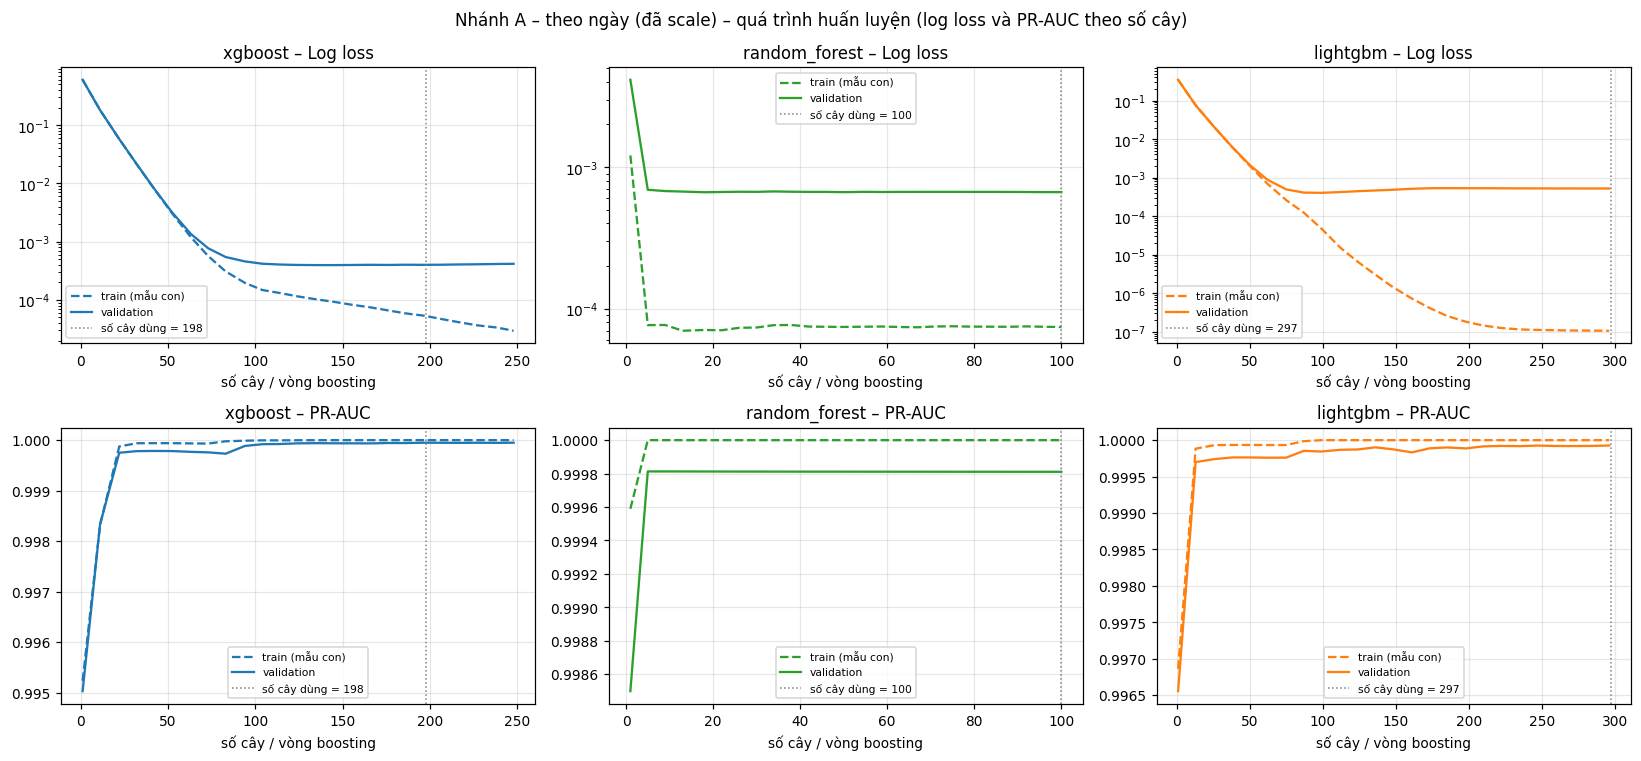

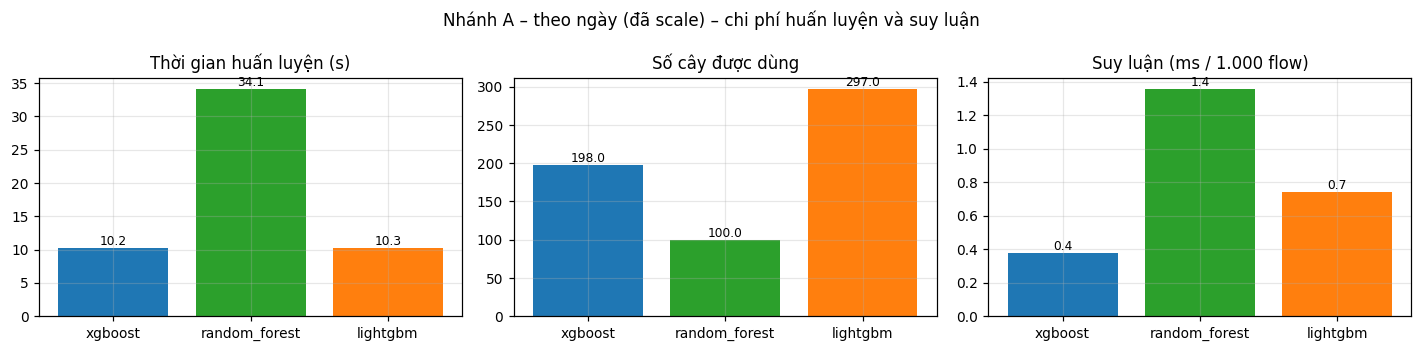


=== Cuối quá trình huấn luyện: train so với validation (khoảng cách lớn -> có dấu hiệu overfit) ===
               logloss | train (mẫu con)  logloss | validation  pr_auc | train (mẫu con)  pr_auc | validation  khoảng cách logloss (val − train)
model                                                                                                                                           
lightgbm                         0.00000               0.00052                       1.0              0.99993                            0.00052
random_forest                    0.00007               0.00067                       1.0              0.99981                            0.00059
xgboost                          0.00003               0.00042                       1.0              0.99995                            0.00039


In [5]:
# Chỉ số theo số cây, tính trên train (mẫu con 200.000 dòng, stratify) và validation – không dùng test
Xs_tr, ys_tr = L.train_subsample(data, n=20000 if SMOKE else 200000)
sets = {"train (mẫu con)": (Xs_tr, ys_tr), "validation": (data["Xva"], data["yva"])}
curves = pd.concat([L.learning_curve(m, models[m], sets) for m in L.MODELS], ignore_index=True)
curves.to_csv(OUT / "learning_curves.csv", index=False, float_format="%.6f")
L.plot_learning_curves(curves, info.set_index("model").n_trees.to_dict(),
                       f"{L.BRANCH_NAME[BRANCH]} – quá trình huấn luyện (log loss và PR-AUC theo số cây)",
                       FIG / "1_learning_curves.png"); plt.show()
L.plot_time(info, f"{L.BRANCH_NAME[BRANCH]} – chi phí huấn luyện và suy luận", FIG / "2_time.png"); plt.show()

last = curves.sort_values("n_trees").groupby(["model", "set"]).tail(1).pivot(index="model", columns="set", values=["logloss", "pr_auc"])
last.columns = [f"{a} | {b}" for a, b in last.columns]
last["khoảng cách logloss (val − train)"] = last["logloss | validation"] - last["logloss | train (mẫu con)"]
L.show(last, "Cuối quá trình huấn luyện: train so với validation (khoảng cách lớn -> có dấu hiệu overfit)", 5)

## 5. Bộ đánh giá chung
### 5.1. Ngưỡng (validation) và chỉ số

In [6]:
p_val = {m: models[m].predict_proba(data["Xva"])[:, 1] for m in L.MODELS}
p_test = {m: models[m].predict_proba(data["Xte"])[:, 1] for m in L.MODELS}
thr = {m: L.thresholds_from_val(data["yva"], p_val[m]) for m in L.MODELS}
val_rows = pd.DataFrame(sum([L.evaluate(m, data["yva"], p_val[m], thr[m], split="val") for m in L.MODELS], []))
test_rows = pd.DataFrame(sum([L.evaluate(m, data["yte"], p_test[m], thr[m], labels=data["mte"].Label) for m in L.MODELS], []))
val_rows.to_csv(OUT / "metrics_val.csv", index=False, float_format="%.6f")
test_rows.to_csv(OUT / "metrics_test.csv", index=False, float_format="%.6f")

print("\n=== Ngưỡng chọn trên validation ===")
print(pd.DataFrame(thr).T.map(lambda v: f"{v:.4g}").to_string())
cols = ["model", "rule", "threshold", "recall", "fpr", "precision", "f1", "fn", "fp", "pr_auc", "roc_auc"]
L.show(val_rows[val_rows.scope == "ALL"][cols].set_index(["model", "rule"]), "VALIDATION")
L.show(test_rows[test_rows.scope == "ALL"][cols].set_index(["model", "rule"]), "TEST")
gap = (val_rows[val_rows.scope == "ALL"].set_index(["model", "rule"])[["recall", "fpr"]]
       .join(test_rows[test_rows.scope == "ALL"].set_index(["model", "rule"])[["recall", "fpr"]], lsuffix=" val", rsuffix=" test"))
gap["recall giảm val→test"] = gap["recall val"] - gap["recall test"]
L.show(gap, "Validation so với test")


=== Ngưỡng chọn trên validation ===
                   fpr1%    fpr0.1%  0.5
xgboost        6.188e-05  0.0008294  0.5
random_forest       0.01       0.03  0.5
lightgbm       1.303e-08  4.892e-07  0.5

=== VALIDATION ===
                       threshold  recall     fpr  precision      f1  fn    fp  pr_auc  roc_auc
model         rule                                                                            
xgboost       fpr1%       0.0001     1.0  0.0100     0.9501  0.9744   0  1407  0.9999      1.0
              fpr0.1%     0.0008     1.0  0.0010     0.9948  0.9974   0   140  0.9999      1.0
              0.5         0.5000     1.0  0.0000     0.9997  0.9999   0     7  0.9999      1.0
random_forest fpr1%       0.0100     1.0  0.0049     0.9750  0.9874   0   686  0.9998      1.0
              fpr0.1%     0.0300     1.0  0.0008     0.9956  0.9978   0   119  0.9998      1.0
              0.5         0.5000     1.0  0.0000     0.9998  0.9999   1     6  0.9998      1.0
lightgbm      fpr1%

### 5.2. Biểu đồ đánh giá

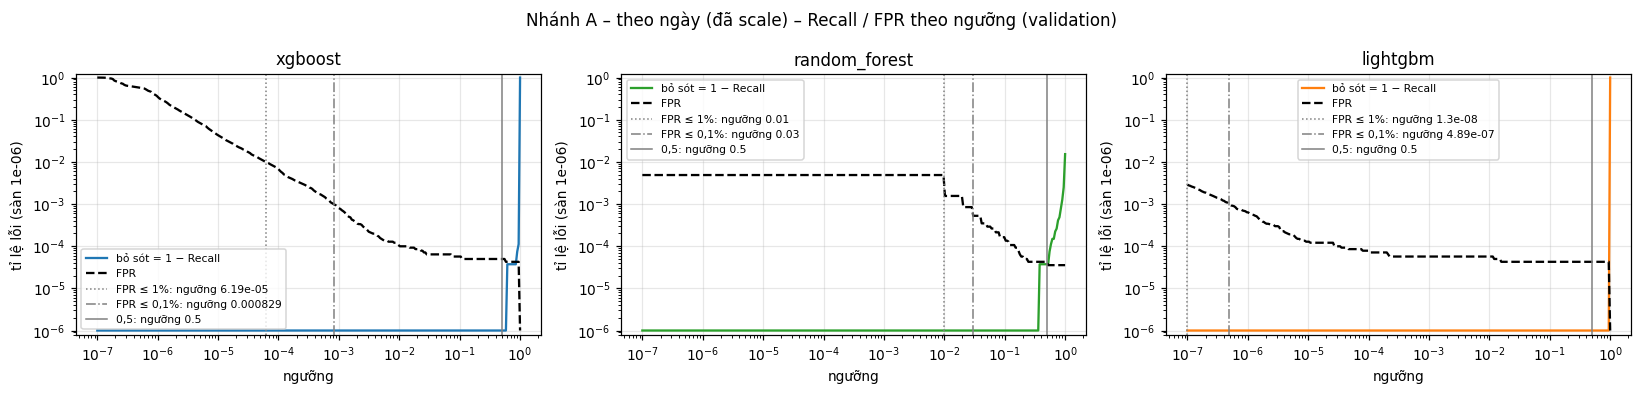

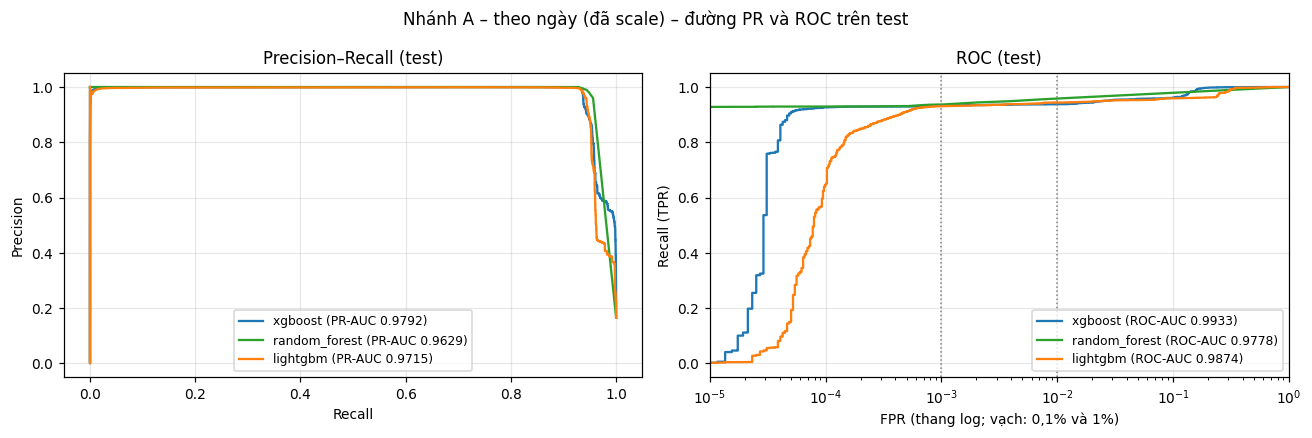

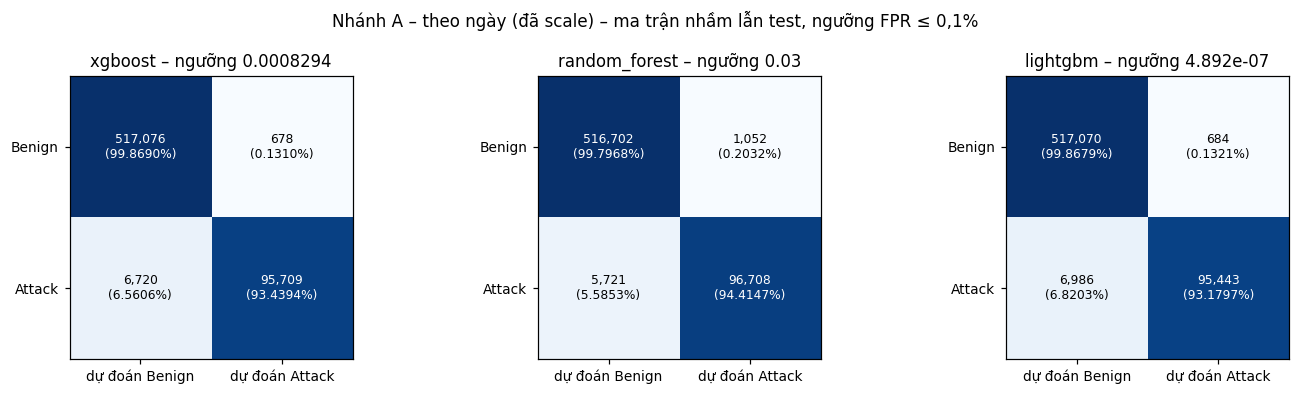

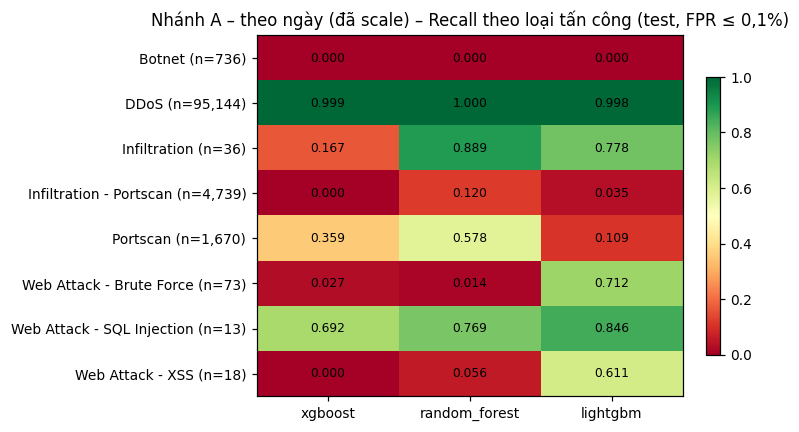

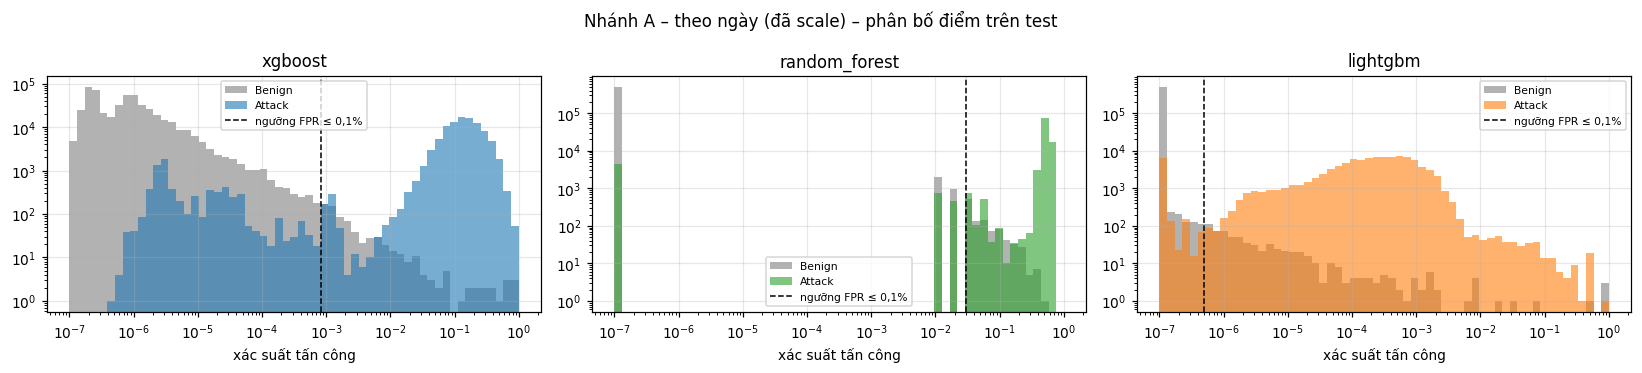

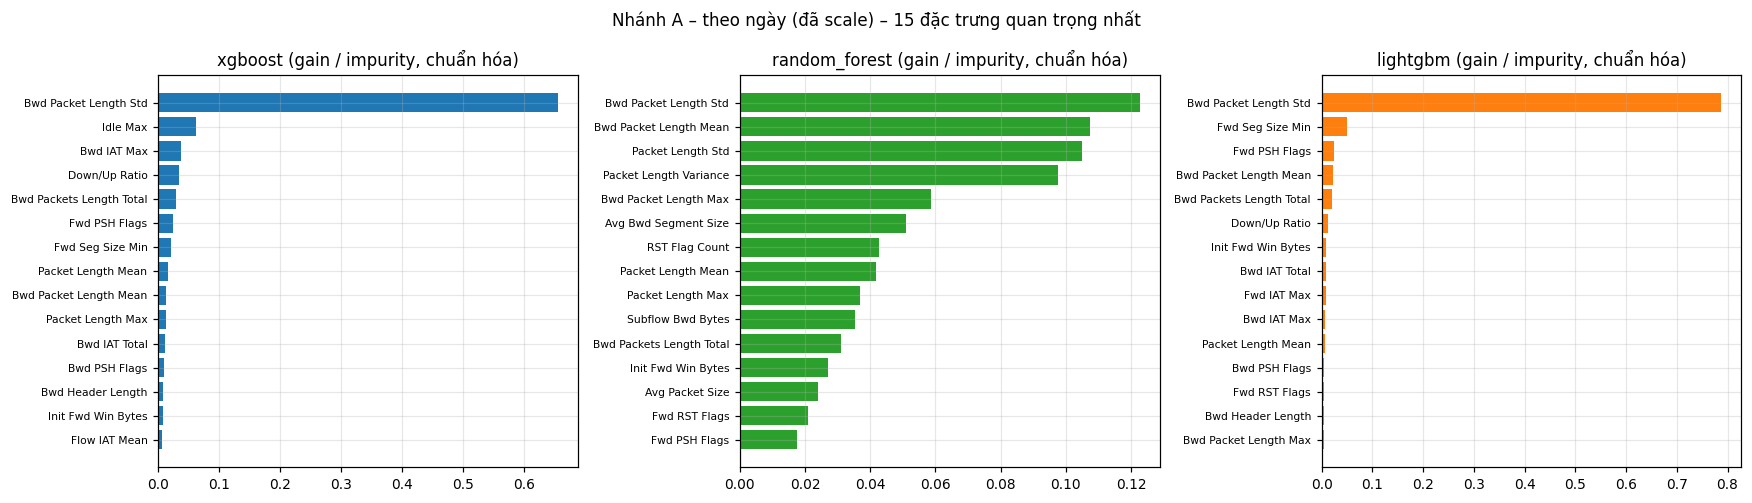

In [7]:
T = L.BRANCH_NAME[BRANCH]
L.plot_threshold_sweep(p_val, data["yva"], thr, f"{T} – Recall / FPR theo ngưỡng (validation)", FIG / "3_threshold_sweep.png"); plt.show()
L.plot_pr_roc(p_test, data["yte"], f"{T} – đường PR và ROC trên test", FIG / "4_pr_roc.png"); plt.show()
L.plot_confusions(test_rows, L.MAIN_RULE, T, FIG / "5_confusion.png"); plt.show()
L.plot_per_attack(test_rows, L.MAIN_RULE, T, FIG / "6_per_attack.png"); plt.show()
L.plot_score_hist(p_test, data["yte"], thr, T, FIG / "7_score_hist.png"); plt.show()
imp = L.plot_feature_importance(models, data["features"], T, path=FIG / "8_feature_importance.png"); plt.show()
imp.to_csv(OUT / "feature_importance.csv", float_format="%.6f")

## 6. So sánh 3 mô hình trong Nhánh A


=== Nhánh A – theo ngày (đã scale) – SO SÁNH 3 MÔ HÌNH TRÊN TEST ===
model                                   xgboost  random_forest      lightgbm
recall @fpr1%                           0.93781        0.95610       0.94396
recall @fpr0.1%                         0.93439        0.94415       0.93180
recall @0.5                             0.01089        0.66664       0.00002
FPR @fpr1%                              0.01129        0.00783       0.01094
FPR @fpr0.1%                            0.00131        0.00203       0.00132
FPR @0.5                                0.00001        0.00000       0.00001
FN @fpr1%                            6370.00000     4497.00000    5740.00000
FN @fpr0.1%                          6720.00000     5721.00000    6986.00000
FN @0.5                            101314.00000    34146.00000  102427.00000
FP @fpr1%                            5845.00000     4054.00000    5665.00000
FP @fpr0.1%                           678.00000     1052.00000     684.00000
FP @0.

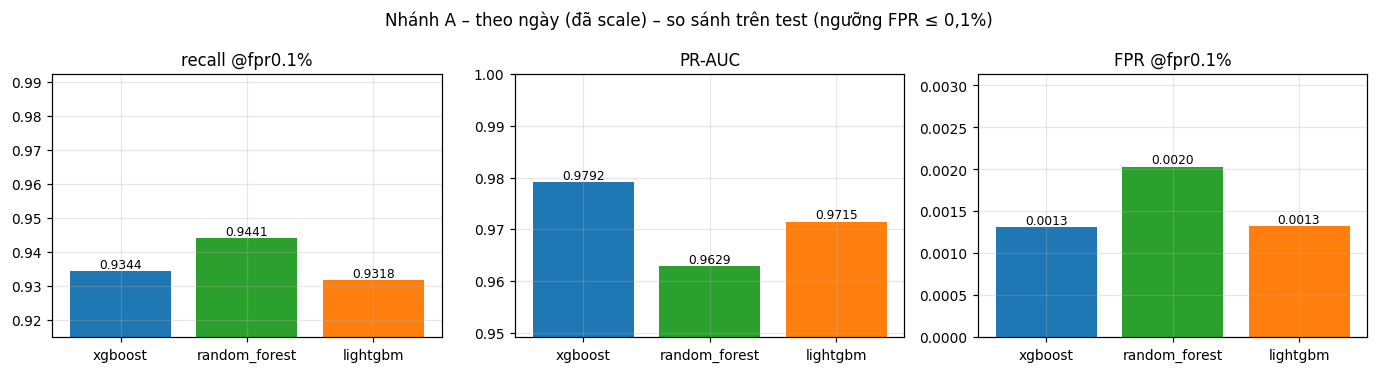


=== Recall theo loại tấn công (test, FPR ≤ 0,1%) ===
model                           n  lightgbm  random_forest  xgboost
scope                                                              
Botnet                        736    0.0000         0.0000   0.0000
DDoS                        95144    0.9984         0.9998   0.9994
Infiltration                   36    0.7778         0.8889   0.1667
Infiltration - Portscan      4739    0.0350         0.1205   0.0002
Portscan                     1670    0.1090         0.5778   0.3593
Web Attack - Brute Force       73    0.7123         0.0137   0.0274
Web Attack - SQL Injection     13    0.8462         0.7692   0.6923
Web Attack - XSS               18    0.6111         0.0556   0.0000

=== Recall tổng bị chi phối bởi loại đông nhất -> xem thêm Recall trung bình theo loại và Recall khi bỏ loại đông nhất ===
               recall TB theo loại @fpr0.1%  recall bỏ loại đông nhất @fpr0.1% loại đông nhất  tỉ lệ loại đông nhất
lightgbm                  

In [8]:
cmp = L.compare_table(test_rows, info)
cmp.to_csv(OUT / "compare_models_test.csv", float_format="%.6f")
L.show(cmp.T, f"{L.BRANCH_NAME[BRANCH]} – SO SÁNH 3 MÔ HÌNH TRÊN TEST", 5)
best, rank = L.rank_models(val_rows, info)
L.show(rank, "Xếp hạng theo quy tắc chung (chỉ validation)", 6)
print(f"\n>>> Mô hình xếp hạng 1 của {L.BRANCH_NAME[BRANCH]}: {best}")
L.plot_compare_bars(cmp, [f"recall @{L.MAIN_RULE}", "PR-AUC", f"FPR @{L.MAIN_RULE}"],
                    f"{L.BRANCH_NAME[BRANCH]} – so sánh trên test (ngưỡng {L.RULE_VI[L.MAIN_RULE]})",
                    FIG / "9_compare_bars.png"); plt.show()
pa = test_rows[(test_rows.scope != "ALL") & (test_rows.rule == L.MAIN_RULE)].pivot(index="scope", columns="model", values="recall")
pa.insert(0, "n", test_rows[(test_rows.scope != "ALL") & (test_rows.rule == L.MAIN_RULE)].groupby("scope").n.first())
L.show(pa, f"Recall theo loại tấn công (test, {L.RULE_VI[L.MAIN_RULE]})")
pts = L.per_type_summary(test_rows)
L.show(pts, "Recall tổng bị chi phối bởi loại đông nhất -> xem thêm Recall trung bình theo loại và Recall khi bỏ loại đông nhất")

## 7. LOFO – chẩn đoán khả năng tổng quát hóa (chỉ dữ liệu Thứ 2–4)

In [9]:
RUN_LOFO = True
if RUN_LOFO:
    lofo_df = L.lofo(data, use_gpu=USE_GPU)
    lofo_df.to_csv(OUT / "lofo.csv", index=False, float_format="%.6f")
    L.show(lofo_df.set_index(["held_out", "model"]), "LOFO: phát hiện họ tấn công bị giữ lại (không dùng test)")
    lofo_rank = lofo_df.groupby("model")[["recall@FPR≤0,1%", "recall@FPR≤1%", "pr_auc"]].mean().sort_values("recall@FPR≤0,1%", ascending=False)
    L.show(lofo_rank, "LOFO trung bình 2 lượt")
    print(f"LOFO đứng đầu: {lofo_rank.index[0]} | quy tắc chung (validation): {best}"
          + (" -> trùng." if lofo_rank.index[0] == best else " -> KHÁC: validation cùng ngày không phân biệt được khả năng tổng quát; nêu rõ khi báo cáo."))

17:44:35 | LOFO giữ lại DoS – xgboost: recall@FPR≤0,1% = 0.0002 (6s)
17:44:57 | LOFO giữ lại DoS – random_forest: recall@FPR≤0,1% = 0.0711 (22s)
17:45:01 | LOFO giữ lại DoS – lightgbm: recall@FPR≤0,1% = 0.0066 (4s)
17:45:18 | LOFO giữ lại BruteForce – xgboost: recall@FPR≤0,1% = 0.0000 (17s)
17:46:16 | LOFO giữ lại BruteForce – random_forest: recall@FPR≤0,1% = 0.0017 (58s)
17:46:23 | LOFO giữ lại BruteForce – lightgbm: recall@FPR≤0,1% = 0.0000 (7s)

=== LOFO: phát hiện họ tấn công bị giữ lại (không dùng test) ===
                          n_held_out  pr_auc  recall@FPR≤1%  recall@FPR≤0,1%
held_out   model                                                            
DoS        xgboost            171755  0.6709         0.0019           0.0002
           random_forest      171755  0.5809         0.0711           0.0711
           lightgbm           171755  0.7149         0.0186           0.0066
BruteForce xgboost              6933  0.1493         0.0006           0.0000
           random_fo

## 8. Lưu mô hình và kết quả

In [10]:
sha = {}
for m in L.MODELS:
    extra = {"rank_in_branch": int(rank.loc[m, "hạng"]), "source": info.set_index("model").loc[m, "nguồn"]}
    sha[m] = L.save_bundle(L.make_bundle(models[m], data, m, thr[m], extra=extra), OUT / "models" / f"{m}.joblib")
pred = data["mte"].copy()
for m in L.MODELS:
    pred[f"p_{m}"] = p_test[m].astype(np.float32)
pred.to_parquet(OUT / "test_predictions.parquet", index=False)
manifest = {
    "branch": BRANCH, "branch_name": L.BRANCH_NAME[BRANCH], "split": data["split"], "data_source": data["source"],
    "scaler_file": data["scaler_file"], "smoke": SMOKE, "sizes": {k: int(len(data[f"y{k}"])) for k in ("tr", "va", "te")},
    "params": L.PARAMS, "select_rule": L.SELECT_RULE, "best": best, "ranking_val": rank.reset_index().to_dict("records"),
    "thresholds": thr, "train_info": info.to_dict("records"), "models_sha256": sha,
    "test_main_rule": {m: {k: float(v) for k, v in cmp.loc[m, [f"recall @{L.MAIN_RULE}", f"FPR @{L.MAIN_RULE}", "PR-AUC"]].items()} for m in L.MODELS},
    "versions": L.versions(), "created": time.strftime("%Y-%m-%d %H:%M:%S"),
}
(OUT / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Đã lưu 3 mô hình:", OUT / "models")
print("Biểu đồ          :", FIG)
print("Bảng số liệu     :", sorted(p.name for p in OUT.glob("*.csv")))
print(f"\n=== TÓM TẮT {L.BRANCH_NAME[BRANCH]} ===")
for m in L.MODELS:
    r = cmp.loc[m]
    print(f"{m:14s} recall@FPR≤0,1% = {r[f'recall @{L.MAIN_RULE}']:.4f} | FPR = {r[f'FPR @{L.MAIN_RULE}']:.5f} | "
          f"PR-AUC = {r['PR-AUC']:.4f} | {'<- hạng 1' if m == best else ''}")

Đã lưu 3 mô hình: E:\Thuc tap\Nhanh_AB_scaled\outputs\A\models
Biểu đồ          : E:\Thuc tap\Nhanh_AB_scaled\outputs\A\figures
Bảng số liệu     : ['compare_models_test.csv', 'feature_importance.csv', 'learning_curves.csv', 'lofo.csv', 'metrics_test.csv', 'metrics_val.csv']

=== TÓM TẮT Nhánh A – theo ngày (đã scale) ===
xgboost        recall@FPR≤0,1% = 0.9344 | FPR = 0.00131 | PR-AUC = 0.9792 | <- hạng 1
random_forest  recall@FPR≤0,1% = 0.9441 | FPR = 0.00203 | PR-AUC = 0.9629 | 
lightgbm       recall@FPR≤0,1% = 0.9318 | FPR = 0.00132 | PR-AUC = 0.9715 | 
